# 1. Preparer, as a Python library

The analyzer needs three inputs besides the sample data, and `preparer` builds all three:

1. **Pixel geometry CSV**: one row per detector pixel with its TOF→Q constant, from the NOMAD
   instrument definition (IDF) and, optionally, a diffraction calibration.
2. **Background CSV**: I(Q) of the empty sample can, reduced from NeXus event files.
3. **Normalization CSV**: I(Q) of a vanadium rod with its small Bragg peaks stripped, used to
   divide out the detector and spectrum response.

The background and normalization CSVs also record the total proton charge and duration of the runs
they came from, so the analyzer can scale them to the sample's exposure.

This step is the same whichever sample source you analyze afterwards (NeXus file, ADARA file or
live ADARA stream), so there is one preparer notebook per method and not per source.

## Data used in these walkthroughs

| Role | Format | Run | ONCat title | Duration | Proton charge | Location |
| --- | --- | --- | --- | --- | --- | --- |
| Sample | NeXus | NOM_243708 | Diamond at temperature 300.0 K | 2:44 | 0.23 C | `nexus_files/diamond/NOM_243708.nxs.h5` (1.7 GB) |
| Sample (optional) | NeXus | NOM_243709 | Diamond at temperature 300.0 K | 26:55 | 2.00 C | `nexus_files/diamond/NOM_243709.nxs.h5` (15.4 GB) |
| Background | NeXus | NOM_243710 | MT_6mm_PAC at temperature 300.01 K (empty PAC06 can) | 24:02 | 2.00 C | `nexus_files/mt_pac_can/NOM_243710.nxs.h5` |
| Background | NeXus | NOM_243711 | MT_6mm_PAC at temperature 299.99 K (empty PAC06 can) | 24:03 | 2.00 C | `nexus_files/mt_pac_can/NOM_243711.nxs.h5` |
| Normalization | NeXus | NOM_243712 | V_rod at temperature 300.01 K (vanadium rod) | 24:03 | 2.00 C | `nexus_files/vanadium/NOM_243712.nxs.h5` (12 GB) |
| Sample | ADARA | 244114 | Diamond at temperature 299.99 K | 4:48 | 0.40 C | `../nomad-adara-carbon-share/20260619-140639.403016382-run-244114/` (16 files, 3.2 GB) |
| Calibration | HDF5 | 243451 | NOMAD shifter calibration, 2026-06-09 | | | `tests/data/calibration/NOMAD_243451_2026-06-09_shifter.h5` |

The NeXus runs are IPTS-37412 (2026-06-12); the ADARA run is IPTS-37098 (2026-06-19). Both diamond
samples sit in a PAC06 can, so the same empty-can background and vanadium normalization serve
both, and the 2026-06-09 calibration is the most recent one before either. Titles, durations and
charges are from `oncat-nomad.csv` in the repository root.

**Runtime:** each step reads whole event files, but the reduction is vectorized with numpy: about
20 s for the 4 GB of background and a minute for the 12 GB vanadium run from local disk.

The CLI calls the same functions used here, so the CSVs are identical. Calling them directly also hands back the reduced arrays, without a round trip through the CSV.

## Setup

Every path below is relative to the repository root, so the commands are the same ones you would
type in a terminal from there.

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root so every path matches the README and the terminal commands.
REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
os.chdir(REPO_ROOT)
# Shell cells resolve `live_stream_analysis` and `python` from this kernel's environment.
os.environ["PATH"] = f"{Path(sys.executable).parent}{os.pathsep}{os.environ['PATH']}"

OUTPUT_DIR = Path("notebooks/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Working directory: {Path.cwd()}")

Working directory: /home/ntm/projects/illumine/live_stream_analysis


## Step 1: pixel geometry from the IDF and calibration

`--calibration-file` replaces each pixel's ideal TOF→Q constant with the calibrated DIFC, and adds
`difc`, `difa`, `tzero` and `use` columns. Pixels with `use = 0` are masked by the analyzer. On
NOM_243708, the calibrated geometry puts the diamond reflections within about 0.001 1/Å of their
literature positions; the uncalibrated one is about 0.75 % low in Q
(see `scripts/live_comparison/README.md`).

The same CSV serves both sources. Only the analyzer's `--tof-tick-us` differs: 1.0 for NeXus, whose
TOF is in µs, and 0.1 for ADARA, whose TOF is in 100 ns ticks. (The alternative is a second CSV
written with `--q-matrix-scale 10` and used with `--tof-tick-us 1.0`.)

In [2]:
from live_stream_analysis.preparer import run_preparer

n_pixels, n_q_bins = run_preparer(
    idf_file=Path("tests/data/idf/NOMAD_Definition.xml"),
    calibration_file=Path("tests/data/calibration/NOMAD_243451_2026-06-09_shifter.h5"),
    pixel_geometry_csv=OUTPUT_DIR / "pixel_geometry_calibrated.csv",
    iq_csv=OUTPUT_DIR / "synthetic_iq.csv",
    # These shape only the synthetic I(Q) sanity check, not the geometry; they are the CLI defaults.
    x_min=1000.0,
    x_max=20000.0,
    bin_width=50.0,
    q_bins=400,
)
print(f"{n_pixels} pixels written to {OUTPUT_DIR / 'pixel_geometry_calibrated.csv'}")

101376 pixels written to notebooks/output/pixel_geometry_calibrated.csv


## Step 2: background from the empty-can runs

Repeat `--nexus-file` to combine runs. Counts are summed, and so are the recorded proton charge and
duration.

`reduce_nexus_files` returns a `ReductionResult`; `write_reduction_csv` writes it.

In [3]:
import time

from live_stream_analysis.preparer import reduce_nexus_files, write_reduction_csv

# The fixed binning the preparer CLI uses; the analyze notebooks histogram on the same grid.
REDUCTION = dict(q_min=0.0, q_max=40.0, q_bin_size=0.02, tof_tick_us=1.0, peak_window=31, peak_z_threshold=3.0)

started = time.monotonic()
background = reduce_nexus_files(
    nexus_files=[Path("nexus_files/mt_pac_can/NOM_243710.nxs.h5"), Path("nexus_files/mt_pac_can/NOM_243711.nxs.h5")],
    mode="background",
    **REDUCTION,
)
write_reduction_csv(background, OUTPUT_DIR / "background.csv")
print(f"Background: {background.total_counts:,} counts, {background.proton_charge_pc:.4g} pC, "
      f"{background.duration_s:.1f} s, reduced in {time.monotonic() - started:.0f} s")

Background: 432,632,851 counts, 4e+12 pC, 2885.6 s, reduced in 11 s


## Step 3: normalization from the vanadium rod

`--mode normalization` smooths the vanadium pattern and replaces points more than
`--peak-z-threshold` standard deviations above the smoothed baseline, which removes vanadium's weak
Bragg peaks. `--peak-window` is the smoothing window in bins.

In [4]:
started = time.monotonic()
normalization = reduce_nexus_files(
    nexus_files=[Path("nexus_files/vanadium/NOM_243712.nxs.h5")],
    mode="normalization",
    **REDUCTION,
)
write_reduction_csv(normalization, OUTPUT_DIR / "normalization.csv")
print(f"Normalization: {normalization.total_counts:,} counts, {normalization.proton_charge_pc:.4g} pC, "
      f"{normalization.duration_s:.1f} s, reduced in {time.monotonic() - started:.0f} s")

Normalization: 1,390,859,869 counts, 2.001e+12 pC, 1443.9 s, reduced in 27 s


## Step 4: diamond reference reflections

Not a preparer output, but the analyze notebooks mark these expected peak positions on the result
as an absolute check of the Q axis. `diamond_reference.py` is a standalone script, not part of the package.

In [5]:
import subprocess

_ = subprocess.run(
    [sys.executable, "scripts/live_comparison/diamond_reference.py", "--q-max", "40",
     "--output-csv", str(OUTPUT_DIR / "diamond_reflections.csv")],
    check=True,
)

a = 3.56712 A -> 124 allowed reflections up to Q = 40.0
Wrote /home/ntm/projects/illumine/live_stream_analysis/notebooks/output/diamond_reflections.csv

hkl                d (A)   Q (1/A)  mult    rel I
111               2.0595    3.0509     8   100.00
220               1.2612    4.9820    12    41.37
311               1.0755    5.8420    24    21.62
400               0.8918    7.0457     6     5.01
331               0.8184    7.6778    24     7.02
422               0.7281    8.6291    24     8.63
333/511           0.6865    9.1526    32     4.49
440               0.6306    9.9641    12     2.35
531               0.6030   10.4207    48     3.89
620               0.5640   11.1402    24     2.92
533               0.5440   11.5504    24     1.25
444               0.5149   12.2035     8     0.65


## Look at what was produced

Background and vanadium divided by their own proton charge, which is the scale the analyzer puts
them on before subtracting and dividing. Here the arrays come straight from the `ReductionResult` objects.

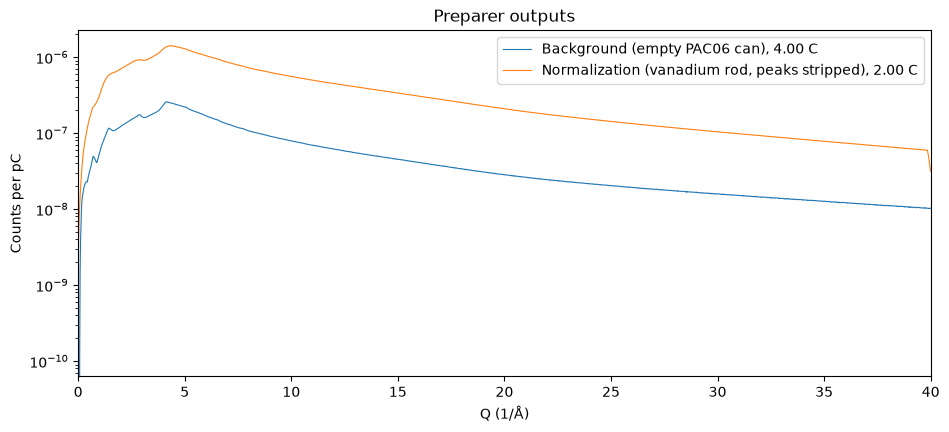

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4.5))
for label, result in [("Background (empty PAC06 can)", background), ("Normalization (vanadium rod, peaks stripped)", normalization)]:
    ax.plot(result.q_values, result.intensity / result.proton_charge_pc, linewidth=0.8,
            label=f"{label}, {result.proton_charge_pc / 1e12:.2f} C")
ax.set(xlim=(0, 40), xlabel="Q (1/Å)", ylabel="Counts per pC", yscale="log", title="Preparer outputs")
ax.legend()
plt.show()

## A caveat worth knowing

The background and vanadium reductions use the instrument geometry embedded in each NeXus file,
**without** the calibration, while the sample is histogrammed with the calibrated geometry from
step 1. The two Q axes therefore differ by the calibration's correction, about 0.75 % on NOMAD at
this time. The vanadium is smooth after peak stripping, so this matters little there; features in
the background can land a fraction of a bin away from the matching features in the sample.

**Next:** pick an analyze notebook: `02_analyze_nexus_*`, `03_analyze_adara_file_*` or
`04_analyze_adara_stream_*`.